In [2]:
from dotenv import load_dotenv
load_dotenv()

True

In [1]:
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START,END
from langgraph.graph.message import add_messages


In [2]:
class State(TypedDict):
    # State extend TypedDict so in runtime state is a dict.
    # Type of messages is list
    # add_messages is a reducer
    messages:Annotated[list,add_messages]


In [5]:
from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-120b")

In [7]:
# Node
# LangGraph appends the new AI message to the existing messages.
def chatbot(state:State):
    return {"messages":[llm.invoke(state.get("messages"))]}

In [8]:
graph_builder = StateGraph(State)
# Add node
graph_builder.add_node("chatbot",chatbot)
#Add edge
graph_builder.add_edge(START,"chatbot")
graph_builder.add_edge("chatbot",END)
# Compile the graph
graph = graph_builder.compile()

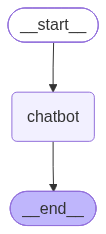

In [9]:
# Display the graph
from IPython.display import Image,display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [16]:
response = graph.invoke({"messages":["Hi"]})
response

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='b2264661-04f4-4165-864c-10c7b2674239'),
  AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hi". We need to respond. It\'s a simple greeting. Should respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 39, 'prompt_tokens': 72, 'total_tokens': 111, 'completion_time': 0.081602774, 'completion_tokens_details': {'reasoning_tokens': 21}, 'prompt_time': 0.002668844, 'prompt_tokens_details': None, 'queue_time': 0.158534695, 'total_time': 0.084271618}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_c3da0d4bb9', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1e769-c61d-7255-b678-ef4f00e76ed7-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 39, 'total_tokens': 111, 'output_token_details': {'reasonin

In [17]:
response["messages"][-1].content

'Hello! How can I help you today?'

In [ ]:
response = graph.invoke({"messages":response["messages"] +  ["How are you"]})

## Example With Tool

In [6]:
from langchain.tools import tool
from langchain_tavily import TavilySearch
@tool
def multiply(a:int,b:int)->int:
    """
    Multlyply two number
    args:
        a(int)->First Number
        b(int)->Second Number
    return:
        int->value o a multiply b
    """
    return a*b;

tavly_search = TavilySearch(max_results = 2)

tools = [multiply,tavly_search]



In [4]:
tavly_search.invoke("Letest news aboth nvidia")

{'query': 'Letest news aboth nvidia',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://superpowerdaily.com/companies/nvidia',
   'title': 'Nvidia News, Products, Models & Company Updates | Superpower Daily',
   'content': 'EarningsBusiness\n\n### Nvidia heads into November 17 earnings under interim CEO Colette Kress\n\nAnalysts expect sharp earnings growth, but a steep loss of market value raises the stakes for the company’s first results since Jensen Huang stepped down.\n\nBusiness\n\n\n\nEarningsBusiness\n\n### Asian tech stocks fall as AI spending worries build ahead of Nvidia earnings\n\nThe selling reached chipmakers, equipment suppliers and Chinese AI developers, while broader market declines were less severe.\n\nPolicy [...] Latest coverage\n\n## What is moving at Nvidia.\n\nView all stories\n\n01 /\n\n### Google publishes AI training results for MLPerf’s first coding-agent benchmark\n\n02 /\n\n### NVIDIA adds CUDA-X science tools, with

In [7]:
from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-120b")
llm_with_tool = llm.bind_tools(tools) # Provide the available tootl information to llm


In [12]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages:Annotated[list,add_messages]

In [27]:
# ChatBot node
def chatBot(state:State):
    return {"messages":[llm_with_tool.invoke(state.get("messages"))]}

In [ ]:
chatBot({"messages":["Hi"]})

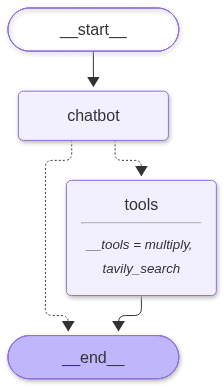

In [29]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode,tools_condition

graph_builder = StateGraph(State)
graph_builder.add_node("chatbot",chatBot)
graph_builder.add_node("tools",ToolNode(tools))
graph_builder.add_edge(START,"chatbot")
graph_builder.add_conditional_edges("chatbot",tools_condition)
graph_builder.add_edge("tools",END)

graph = graph_builder.compile()
graph

In [31]:
response=graph.invoke({"messages":["What is the recent ai news"]})
response

{'messages': [HumanMessage(content='What is the recent ai news', additional_kwargs={}, response_metadata={}, id='18877ed8-d57b-4a54-bd47-eeeb69a555f1'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "What is the recent ai news". Need to provide recent AI news. As of current date 2026-11-17. Need up-to-date info. Use tavily_search to get recent AI news. Probably search query "latest AI news November 2026". Use tool.', 'tool_calls': [{'id': 'fc_db51fbb3-0e29-4d4c-8024-67266c7f4e04', 'function': {'arguments': '{"query":"latest AI news November 2026","search_depth":"advanced","time_range":"day","topic":"news"}', 'name': 'tavily_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 121, 'prompt_tokens': 373, 'total_tokens': 494, 'completion_time': 0.255499496, 'completion_tokens_details': {'reasoning_tokens': 63}, 'prompt_time': 0.020033826, 'prompt_tokens_details': None, 'queue_time': 0.156133459, 'total_time': 0.27553332

In [32]:
response=graph.invoke({"messages":"What is 5 multiplied by 2"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 5 multiplied by 2
================================== Ai Message ==================================

5 multiplied by 2 equals **10**.


In [ ]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"}) # In this case ai cannot give the resul of 5*10 as we did not send the tool reselt to llm , direclt exit from tool call.
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_f5859d8e-eda6-48be-ad69-365636101c2c)
 Call ID: fc_f5859d8e-eda6-48be-ad69-365636101c2c
  Args:
    query: latest AI news
    search_depth: advanced
    time_range: week
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://martech.org/the-latest-ai-powered-martech-news-and-releases", "title": "The latest AI-powered martech news and releases", "content": "## October 22, 2026\n\nAdfury launched an AI-native rich media tool for brands on Walmart. It generates interactive below-the-fold content modules, formats product detail pages, and syncs brand assets across retail

### ReAct Agent Architecture


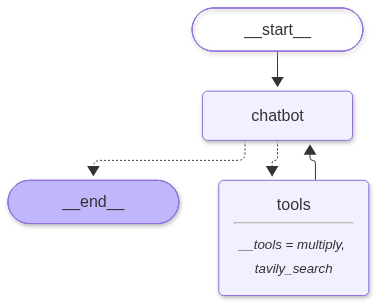

In [34]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode,tools_condition

graph_builder = StateGraph(State)
graph_builder.add_node("chatbot",chatBot)
graph_builder.add_node("tools",ToolNode(tools))
graph_builder.add_edge(START,"chatbot")
graph_builder.add_conditional_edges("chatbot",tools_condition)

graph_builder.add_edge("tools","chatbot")

graph = graph_builder.compile()
graph

In [35]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_c3807697-582d-4786-a06f-a3e01f904367)
 Call ID: fc_c3807697-582d-4786-a06f-a3e01f904367
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: month
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.shrm.org/topics-tools/news/ai-unlocked-4-essential-things-to-know-this-week-november-9", "title": "AI Unlocked: 4 Essential Things to Know This Week, November 9, 2026", "content": "In this week's news roundup, artificial intelligence policies are up for review. U.S. midterm election voters passed data center bans in dozens of com

### Adding Memory In Agentic Graph

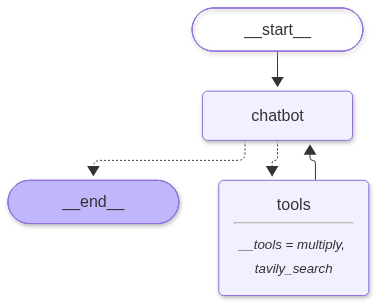

In [36]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode,tools_condition
from langgraph.checkpoint.memory import MemorySaver
memory = MemorySaver()

graph_builder = StateGraph(State)
graph_builder.add_node("chatbot",chatBot)
graph_builder.add_node("tools",ToolNode(tools))
graph_builder.add_edge(START,"chatbot")
graph_builder.add_conditional_edges("chatbot",tools_condition)

graph_builder.add_edge("tools","chatbot")

graph = graph_builder.compile(checkpointer=memory)
graph

In [37]:
config={"configurable":{"thread_id":"1"}}
response=graph.invoke({"messages":"Hi my name is Sujan"},config=config)
response

{'messages': [HumanMessage(content='Hi my name is Sujan', additional_kwargs={}, response_metadata={}, id='f5dab7d4-ec71-4cc2-83c6-241fd4ca93b0'),
  AIMessage(content='Hi Sujan! Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'We need to respond. The user says "Hi my name is Sujan". Likely just a greeting. We can respond politely, ask how we can help.'}, response_metadata={'token_usage': {'completion_tokens': 59, 'prompt_tokens': 373, 'total_tokens': 432, 'completion_time': 0.123187037, 'completion_tokens_details': {'reasoning_tokens': 34}, 'prompt_time': 0.015355528, 'prompt_tokens_details': None, 'queue_time': 0.051014522, 'total_time': 0.138542565}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_05e76be18c', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1ea85-b731-76aa-b3c9-634c6716efb5-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 37

In [38]:
config={"configurable":{"thread_id":"1"}}
response=graph.invoke({"messages":"What is my name"},config=config)
response

{'messages': [HumanMessage(content='Hi my name is Sujan', additional_kwargs={}, response_metadata={}, id='f5dab7d4-ec71-4cc2-83c6-241fd4ca93b0'),
  AIMessage(content='Hi Sujan! Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'We need to respond. The user says "Hi my name is Sujan". Likely just a greeting. We can respond politely, ask how we can help.'}, response_metadata={'token_usage': {'completion_tokens': 59, 'prompt_tokens': 373, 'total_tokens': 432, 'completion_time': 0.123187037, 'completion_tokens_details': {'reasoning_tokens': 34}, 'prompt_time': 0.015355528, 'prompt_tokens_details': None, 'queue_time': 0.051014522, 'total_time': 0.138542565}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_05e76be18c', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1ea85-b731-76aa-b3c9-634c6716efb5-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 37